In [50]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [51]:
!pip install optbinning

In [66]:
# Importamos las librerías
import pandas as pd
from sklearn.model_selection import train_test_split
from optbinning import Scorecard, BinningProcess, OptimalBinning
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from pysal.lib import weights
from pysal.explore import esda
from pysal.model import spreg
import numpy as np
from libpysal.weights import DistanceBand
from esda.moran import Moran

In [53]:
# Imnportamos el conjunto de daros "germacredit"
dt=pd.read_csv('/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/U.Lorenzo Escot/3_Tarea/germancredit.csv')

In [54]:
#Recodifico esta variable creditability (variable objetivo) para que sea binaria
dt["y"]=0
dt.loc[dt["creditability"]=="good",["y"]]=0
dt.loc[dt["creditability"]=="bad", ["y"]]=1
dt.drop(labels='creditability',inplace=True, axis=1)

In [55]:
# Creo la muestra de entrenamiento y de test
dt_train, dt_test = train_test_split(dt, stratify= dt["y"], test_size=.25, random_state=1234)

In [56]:
# Realizamos la trimificación optima de age.in.years
variable="age.in.years"
X=dt_train[variable].values
Y=dt_train['y'].values
optb = OptimalBinning(name=variable, dtype="numerical", solver="cp")
optb.fit(X, Y)
optb.splits
binning_table = optb.binning_table
binning_table.build()

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 25.50)",139,0.185333,81,58,0.417266,-0.513292,0.053122,0.006568
1,"[25.50, 29.50)",146,0.194667,100,46,0.315068,-0.070769,0.000989,0.000124
2,"[29.50, 34.50)",137,0.182667,94,43,0.313869,-0.065203,0.000787,0.000098
3,"[34.50, 36.50)",61,0.081333,51,10,0.163934,0.781943,0.041207,0.005024
4,"[36.50, 38.50)",38,0.050667,30,8,0.210526,0.474458,0.010242,0.001268
5,"[38.50, 41.50)",46,0.061333,35,11,0.239130,0.310155,0.005514,0.000686
6,"[41.50, inf)",183,0.244000,134,49,0.267760,0.158722,0.005946,0.000742
7,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
8,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,750,1.000000,525,225,0.300000,,0.117806,0.014511


In [57]:
# 1. Cargar los datos (asegúrate de que el nombre del archivo coincide con el tuyo)
df = pd.read_excel(r'/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/U.Lorenzo Escot/3_Tarea/DatosPractica_Scoring.xlsx')

In [58]:
# 2. Filtrar solo los clientes aceptados (Cardhldr == 1)
df_accepted = df[df['Cardhldr'] == 1.0].copy()

In [59]:
# 3. Definir la variable objetivo (y) y asegurarnos de que es de tipo entero
y = df_accepted['default'].astype(int).values

In [60]:
# 4. Lista completa de variables predictoras solicitadas
features = [
    'Age', 'Income', 'Exp_Inc', 'Avgexp', 'Ownrent',
    'Selfempl', 'Depndt', 'Inc_per', 'Cur_add', 'Major', 'Active'
]

In [61]:
# 5. Iterar sobre cada variable, calcular su binning óptimo y extraer el IV
iv_results = {}

for col in features:
    # Extraer la variable predictora (x)
    x = df_accepted[col].values

    # Inicializar y ajustar OptimalBinning
    optb = OptimalBinning(name=col, dtype="numerical", solver="cp")
    optb.fit(x, y)

    # *** CORRECCIÓN A CONTINUACIÓN ***
    # Extraer la tabla subyacente y CONSTRUIRLA antes de pedir el IV
    binning_table = optb.binning_table
    binning_table.build() # <-- Esta es la línea que faltaba

    # Ahora sí podemos extraer el valor de la información (IV)
    iv = binning_table.iv
    iv_results[col] = iv

In [62]:
# 6. Imprimir los resultados en el orden exacto del test
print("Valor de la Información (IV) para cada variable:")
print("-" * 45)
for col in features:
    print(f"{col:<10} Respuesta: {iv_results[col]:.6f}")

Valor de la Información (IV) para cada variable:
---------------------------------------------
Age        Respuesta: 0.224977
Income     Respuesta: 0.222999
Exp_Inc    Respuesta: 0.187134
Avgexp     Respuesta: 0.271663
Ownrent    Respuesta: 0.011976
Selfempl   Respuesta: 0.011895
Depndt     Respuesta: 0.005121
Inc_per    Respuesta: 0.156240
Cur_add    Respuesta: 0.192857
Major      Respuesta: 0.030557
Active     Respuesta: 0.804177


In [63]:
gdfm =gpd.read_file("/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/U.Lorenzo Escot/2_Espacial/CartografiasDatos_Python/cartografias/Munic04_ESP.shp")
gdfm_Madrid =gdfm[gdfm['COD_PROV']=='28']
gdfm_Madrid.explore(column='PrecioIn16',
                    scheme='NaturalBreaks',
                    k=9, cmap='YlOrRd',
                    legend=False,
                    style_kwds=dict(fillOpacity=0.8))

/tmp/ipython-input-78429638.py:3: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  wq = weights.contiguity.Queen.from_dataframe(gdfm)
/usr/local/lib/python3.12/dist-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 19 disconnected components.
 There are 8 islands with ids: 816, 2536, 5326, 7061, 7160, 7229, 8106, 8107.
  W.__init__(self, neighbors, ids=ids, **kw)


('WARNING: ', 816, ' is an island (no neighbors)')
('WARNING: ', 2536, ' is an island (no neighbors)')
('WARNING: ', 5326, ' is an island (no neighbors)')
('WARNING: ', 7061, ' is an island (no neighbors)')
('WARNING: ', 7160, ' is an island (no neighbors)')
('WARNING: ', 7229, ' is an island (no neighbors)')
('WARNING: ', 8106, ' is an island (no neighbors)')
('WARNING: ', 8107, ' is an island (no neighbors)')


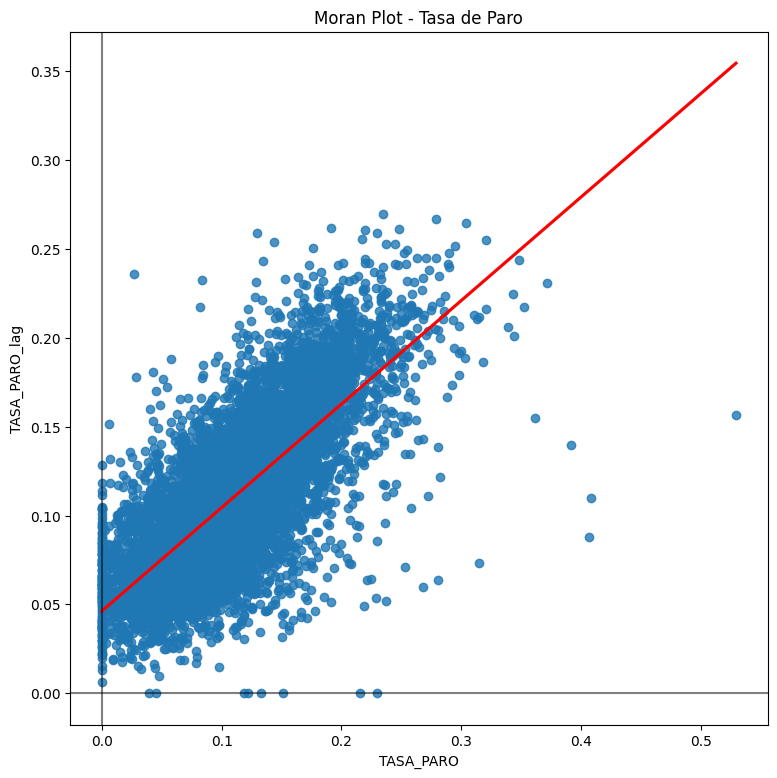

In [64]:
gdfm =gpd.read_file("/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/U.Lorenzo Escot/2_Espacial/CartografiasDatos_Python/cartografias/Munic04_ESP.shp")

wq = weights.contiguity.Queen.from_dataframe(gdfm)
wq.transform = "R"

gdfm["TASA_PARO_lag"] = weights.spatial_lag.lag_spatial(wq, gdfm["TASA_PARO"])


f, ax = plt.subplots(1, figsize=(9, 9))
sns.regplot(
    x="TASA_PARO",
    y="TASA_PARO_lag",
    ci=None,
    data=gdfm,
    line_kws={"color": "r"})
ax.axvline(0, c="k", alpha=0.5)
ax.axhline(0, c="k", alpha=0.5)
ax.set_title("Moran Plot - Tasa de Paro")
plt.show()

In [65]:
gdfm =gpd.read_file("/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/U.Lorenzo Escot/2_Espacial/CartografiasDatos_Python/cartografias/Munic04_ESP.shp")

wq = weights.contiguity.Queen.from_dataframe(gdfm)
wq.transform = "R"



# MODELO (A)

modelo_A = spreg.OLS(
    # Dependent variable
    gdfm[["TASA_PARO"]].values,
    # Independent variables
    gdfm[["RENTPCAP07"]].values,
    # Dependent variable name
    name_y="TASA_PARO",
    # Independent variable name
    name_x=["RENTA_PERCAPITA"])

gdfm["residual"] = modelo_A.u

moran = esda.moran.Moran(gdfm["residual"], wq)
print("I de moran:", moran.I.round(3))
print("p-valor:", moran.p_sim)


# MODELO (B)

modelo_B = spreg.GM_Error_Het(
    # Dependent variable
    gdfm[["TASA_PARO"]].values,
    # Independent variables
    gdfm[["RENTPCAP07"]].values,
    # Spatial weights matrix
    w=wq,
    # Dependent variable name
    name_y="TASA_PARO",
    # Independent variable name
    name_x=["RENTA_PERCAPITA"])

gdfm["mLagresidual"] = modelo_B.e_filtered

moran = esda.moran.Moran(gdfm["mLagresidual"], wq)
print("I de moran:", moran.I.round(3))
print("p-valor:", moran.p_sim)

/tmp/ipython-input-4155063257.py:3: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  wq = weights.contiguity.Queen.from_dataframe(gdfm)
/usr/local/lib/python3.12/dist-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 19 disconnected components.
 There are 8 islands with ids: 816, 2536, 5326, 7061, 7160, 7229, 8106, 8107.
  W.__init__(self, neighbors, ids=ids, **kw)


('WARNING: ', 816, ' is an island (no neighbors)')
('WARNING: ', 2536, ' is an island (no neighbors)')
('WARNING: ', 5326, ' is an island (no neighbors)')
('WARNING: ', 7061, ' is an island (no neighbors)')
('WARNING: ', 7160, ' is an island (no neighbors)')
('WARNING: ', 7229, ' is an island (no neighbors)')
('WARNING: ', 8106, ' is an island (no neighbors)')
('WARNING: ', 8107, ' is an island (no neighbors)')
I de moran: 0.581
p-valor: 0.001
I de moran: -0.066
p-valor: 0.001


In [67]:
# 1. Lectura del fichero de datos
df = pd.read_csv(r'/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/U.Lorenzo Escot/3_Tarea/Data_Housing_Madrid.csv')

# 2. Construcción del GeoDataFrame
gdfm = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.longitude, df.latitude),
    crs='EPSG:4326'
)

# 3. Filtrado por el casco histórico
gdfm_historical = gdfm[gdfm['historical'] == 1].copy()

# --- CÁLCULOS DESCRIPTIVOS ---

total_viviendas = len(df)
viviendas_historico = len(gdfm_historical)
precio_mediano = gdfm_historical['house.price'].median()
precio_maximo = gdfm_historical['house.price'].max()

# 4. Construcción de la matriz de pesos espaciales (Híbrida: Radio + Distancia Inversa)
# threshold = 0.00225 (aprox 250m)
# alpha = -1 (distancia inversa)
# binary = False (para que use los pesos calculados por alpha)
w_hy = DistanceBand.from_dataframe(
    gdfm_historical,
    threshold=0.00225,
    alpha=-1,
    binary=False,
    silence_warnings=True
)

# 5. Análisis de vecindades e islas
# 'islands' son las observaciones sin vecinos dentro del radio
n_islas = len(w_hy.islands)

# Número de vecinos para cada vivienda (excluyendo las islas para la mediana si se desea,
# pero habitualmente se calcula sobre el total)
vecinos_por_vivienda = [w_hy.cardinalities[i] for i in gdfm_historical.index]
mediana_vecinos = np.median(vecinos_por_vivienda)

# 6. Contraste de Autocorrelación Espacial (I de Moran)
# Es necesario estandarizar por filas (transformation='R') para el cálculo de Moran
w_hy.transform = 'R'
moran = Moran(gdfm_historical['house.price'], w_hy)

# --- RESULTADOS PARA EL TEST ---

print(f"1. Número total de viviendas: {total_viviendas}")
print(f"2. Viviendas en el casco histórico: {viviendas_historico}")
print(f"3. Precio mediano (histórico): {precio_mediano}")
print(f"4. Precio máximo (histórico): {precio_maximo}")
print(f"5. Viviendas sin vecinas (islas): {n_islas}")
print(f"6. Mediana de vecinos: {mediana_vecinos}")
print(f"7. I de Moran: {moran.I:.3f}")
print(f"8. p-valor: {moran.p_sim:.3f}")

# Interpretación lógica
if moran.p_sim < 0.05:
    print("\nConclusión: Existe autocorrelación espacial significativa. "
          "El precio de las vecinas SÍ ayuda a estimar el precio.")
else:
    print("\nConclusión: No se detecta autocorrelación significativa.")

1. Número total de viviendas: 10512
2. Viviendas en el casco histórico: 3633
3. Precio mediano (histórico): 4444.0
4. Precio máximo (histórico): 20131.0
5. Viviendas sin vecinas (islas): 106
6. Mediana de vecinos: 21.0
7. I de Moran: 0.326
8. p-valor: 0.001

Conclusión: Existe autocorrelación espacial significativa. El precio de las vecinas SÍ ayuda a estimar el precio.
